# 半教師あり学習と遠距離教師あり学習（Yarowsky・共訓練・マルチインスタンス集約）

書籍 第1章「自然言語処理システムのデザイン」（1-2-3 機械学習ベース、1-3 データ：辞書やコーパス、関連論文 1章 2〜4）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、少数のシードや既存知識ベースからラベル付きデータを拡張・構築する 2 つのアプローチを体験します。

1. **半教師あり学習（1-2-3・関連論文 1章 2・3）**: 少数シードルールと 2 つの独立ビューによる共訓練 (Co-training) と one sense per discourse 制約（Yarowsky アルゴリズム）、単一ビュー自己学習との比較、および閾値低下によるセマンティックドリフト
2. **遠距離教師あり学習 (Distant Supervision)（1-3・関連論文 1章 4）**: 知識ベース (KB) の三つ組とラベルなしコーパスからの訓練データ自動構築、偶然共起ノイズ (False Positive) の分析、およびマルチインスタンス集約による関係抽出

In [1]:
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.pipeline import FeatureUnion

## 1. 半教師あり学習：自己学習（Yarowsky アルゴリズム）と共訓練 (Co-training)（1-2-3・関連論文 1章 2・3）

書籍 1-2-3「機械学習ベース」および関連論文 1章 2（Yarowsky, ACL 1995「*Unsupervised Word Sense Disambiguation Rivaling Supervised Methods*」）・関連論文 1章 3（Collins and Singer, EMNLP 1999「*Unsupervised Models for Named Entity Classification*」）では、少数の高適合率シードから大量のラベルなしテキストを活用して分類器を成長させる**半教師あり学習 (Semi-supervised Learning)** が解説されています。

ここでは固有表現・専門表現の候補を `組織 (ORG)`・`場所・施設 (LOC)`・`システム・製品 (PROD)` の 3 クラスに分類するタスクを設定し、Collins and Singer (1999) に倣って特徴量を次の **2 つの独立したビュー** に分割します。

- **View A（表記・内部特徴）**：候補文字列自体の末尾・接頭・文字バイグラムのみ（文脈には一切触れない）
- **View B（文脈特徴）**：候補の直前・直後に出現する語・助詞・動詞・文字 $n$-gram のみ（候補文字列自体には一切触れない）

さらに Yarowsky (1995) の **one sense per discourse**（同一文書内の同一候補は同じラベルをとる）制約を組み合わせ、各クラスわずか 2 個ずつ・計 6 個の**高適合率シードルール**（表記側のみ）を出発点として、以下を比較します。

1. **① シードルールのみ**（およびシード一致事例のみでの Round 0 教師あり学習）
2. **② 単一ビュー自己学習 (Self-training)**（View A のみ、および View A+B 結合 1 分類器で反復拡大）
3. **③ 共訓練 (Co-training) ＋ one sense per discourse 制約**（View B の高確信度予測 + 談話制約でラベルを広げ View A を学習 → View A の高確信度予測で View B を更新、を Round 1 → 2 → 3 と相互反復）

In [2]:
# 1. 各クラス 2 個ずつ・計 6 個の高適合率シードルール（View A の表記末尾のみ）
SEED_SUFFIXES = {
    "ORG": ("株式会社", "大学"),
    "LOC": ("空港", "駅"),
    "PROD": ("OS", "DB"),
}

def apply_seed_rule(entity):
    for label, suffixes in SEED_SUFFIXES.items():
        if any(entity.endswith(suf) for suf in suffixes):
            return label
    return None

# 2. ラベルなしコーパス（45 文・21 文書; 第4要素は事後監査用であり学習には一切使わない）
unlabeled_data = [
    # --- Wave 0: シードルールに一致する文 (12 文) ---
    ("d01", "明光株式会社が来期の決算見通しを公表した。", "明光株式会社", "ORG"),
    ("d01", "取引先と明光株式会社が業務提携で合意した。", "明光株式会社", "ORG"),
    ("d02", "蒼穹大学が産学連携の新規事業を公表した。", "蒼穹大学", "ORG"),
    ("d02", "地元の自治体と蒼穹大学が包括協定を締結した。", "蒼穹大学", "ORG"),
    ("d03", "新星空港の到着ロビーに大勢の旅行客が並んだ。", "新星空港", "LOC"),
    ("d03", "高速バスで新星空港の正面ゲートに到着した。", "新星空港", "LOC"),
    ("d04", "桜木駅の改札前で同僚と待ち合わせた。", "桜木駅", "LOC"),
    ("d04", "案内図を手に桜木駅の周辺を歩いて散策した。", "桜木駅", "LOC"),
    ("d05", "流星OSの最新版を業務用端末へインストールした。", "流星OS", "PROD"),
    ("d05", "不具合を直すため流星OSをすぐにアップデートした。", "流星OS", "PROD"),
    ("d06", "高速検索が可能な光速DBを社内へ導入した。", "光速DB", "PROD"),
    ("d06", "管理画面から光速DBのライセンスを登録した。", "光速DB", "PROD"),

    # --- Wave 1: 未知表記だが初期文脈で識別可能 + 同一文書内の弱い文脈文 (12 文) ---
    ("d07", "銀河研究所が来期の共同研究の成果を公表した。", "銀河研究所", "ORG"),
    ("d07", "なお銀河研究所は来春に新施設を開設する。", "銀河研究所", "ORG"),
    ("d08", "北風財団が医療支援の助成事業で合意した。", "北風財団", "ORG"),
    ("d08", "これに伴い北風財団の公式窓口が稼働する。", "北風財団", "ORG"),
    ("d09", "青空美術館の到着ロビーに大勢の来場者が並んだ。", "青空美術館", "LOC"),
    ("d09", "昼前に同僚と青空美術館の改札前で待ち合わせた。", "青空美術館", "LOC"),
    ("d10", "晴れた日に若葉図書館の周辺を歩いて散策した。", "若葉図書館", "LOC"),
    ("d10", "帰り道でも若葉図書館の様子を確認した。", "若葉図書館", "LOC"),
    ("d11", "彩雲アプリをスマホ端末へインストールした。", "彩雲アプリ", "PROD"),
    ("d11", "作業後に彩雲アプリの初期設定を済ませた。", "彩雲アプリ", "PROD"),
    ("d12", "翠玉エディタを最新版へすぐにアップデートした。", "翠玉エディタ", "PROD"),
    ("d12", "執筆効率を上げるため翠玉エディタを社内へ導入した。", "翠玉エディタ", "PROD"),

    # --- Wave 2: 獲得済み末尾語形 × 新しい文脈パターン (12 文) ---
    ("d13", "風車研究所は若手向けの奨学金制度を新設した。", "風車研究所", "ORG"),
    ("d13", "記者からの質問に風車研究所の理事長が答えた。", "風車研究所", "ORG"),
    ("d14", "朝霧財団は中小企業向けの支援基金を設立した。", "朝霧財団", "ORG"),
    ("d14", "定例会見で朝霧財団の専務理事が方針を述べた。", "朝霧財団", "ORG"),
    ("d15", "碧海美術館の展示室で特別企画展が開催中だ。", "碧海美術館", "LOC"),
    ("d15", "館内マップで碧海美術館の展示棟を確認した。", "碧海美術館", "LOC"),
    ("d16", "千歳図書館の観覧席が改修工事で増設された。", "千歳図書館", "LOC"),
    ("d16", "日曜日の午後に千歳図書館の自習室へ足を運んだ。", "千歳図書館", "LOC"),
    ("d17", "隼アプリの設定画面から通知音を変更した。", "隼アプリ", "PROD"),
    ("d17", "開発チームが隼アプリのベータ版をビルドした。", "隼アプリ", "PROD"),
    ("d18", "暁エディタのエラーログを詳しく確認した。", "暁エディタ", "PROD"),
    ("d18", "文字コード変換機能を備えた暁エディタを起動した。", "暁エディタ", "PROD"),

    # --- Wave 3: さらに未知の末尾語形 × Round 2 文脈パターン (9 文) ---
    ("d19", "東雲銀行の頭取が記者からの質問に答えた。", "東雲銀行", "ORG"),
    ("d19", "南風協会は技術者向けの奨学金制度を新設した。", "南風協会", "ORG"),
    ("d19", "緑山商事が環境保全の支援基金を設立した。", "緑山商事", "ORG"),
    ("d20", "翡翠博物館の展示室で化石の特別企画展が開催中だ。", "翡翠博物館", "LOC"),
    ("d20", "紅葉体育館の観覧席が改修工事で増設された。", "紅葉体育館", "LOC"),
    ("d20", "白樺ホールの自習室へ休日の午後に足を運んだ。", "白樺ホール", "LOC"),
    ("d21", "春風ブラウザの設定画面から表示形式を変更した。", "春風ブラウザ", "PROD"),
    ("d21", "蒼天エンジンを起動して音声合成をビルドした。", "蒼天エンジン", "PROD"),
    ("d21", "星雲ビューアのエラーログを出力して確認した。", "星雲ビューア", "PROD"),
]

# 3. 未知の評価テスト文（24 文: 6 シードルールに一切マッチしない）
test_data_ssl = [
    # ORG (8 文: 獲得済み末尾 + 中立文脈 4 文 / 完全未知候補名 + Round 2 文脈 4 文)
    ("先日の講演資料で若葉研究所が話題に上った。", "若葉研究所", "ORG"),
    ("この特集記事には海風財団の名前が載っている。", "海風財団", "ORG"),
    ("昨日読んだ書籍の中で大和銀行が触れられていた。", "大和銀行", "ORG"),
    ("友人がまとめた一覧表に富士協会が含まれていた。", "富士協会", "ORG"),
    ("黒潮ホールディングスは若手の奨学金制度を新設した。", "黒潮ホールディングス", "ORG"),
    ("定例会見で雪国電機の専務理事が今後の方針を述べた。", "雪国電機", "ORG"),
    ("山彦ラボは次世代向けの支援基金を設立した。", "山彦ラボ", "ORG"),
    ("記者からの質問に瀬戸内企画の理事長が丁寧に答えた。", "瀬戸内企画", "ORG"),

    # LOC (8 文)
    ("次回のポスターに夕焼け美術館の写真を使う予定だ。", "夕焼け美術館", "LOC"),
    ("パンフレットの表紙に古都図書館が紹介されている。", "古都図書館", "LOC"),
    ("知り合いのブログで潮風博物館が取り上げられた。", "潮風博物館", "LOC"),
    ("配布された冊子にはあさひ体育館の記載があった。", "あさひ体育館", "LOC"),
    ("星見展望台の観覧席が改装工事によって増設された。", "星見展望台", "LOC"),
    ("緑ヶ丘植物園の展示室で珍しい蘭の特別企画展が開催中だ。", "緑ヶ丘植物園", "LOC"),
    ("休日の午後に泉水ドームの広い自習室へ足を運んだ。", "泉水ドーム", "LOC"),
    ("案内マップを開いてあかね広場の展示棟を確認した。", "あかね広場", "LOC"),

    # PROD (8 文)
    ("技術ブログの連載で稲妻アプリが取り上げられた。", "稲妻アプリ", "PROD"),
    ("今月の雑誌付録に月光エディタの名前が載っている。", "月光エディタ", "PROD"),
    ("社内の勉強会資料に疾風ブラウザが挙げられていた。", "疾風ブラウザ", "PROD"),
    ("参考書の付録一覧に真昼エンジンが含まれていた。", "真昼エンジン", "PROD"),
    ("花鳥コンパイラの設定画面から文字サイズを変更した。", "花鳥コンパイラ", "PROD"),
    ("高速処理機能を備えた風雅クラウドを起動してテストした。", "風雅クラウド", "PROD"),
    ("チーム全員が白波ツールのエラーログを共有して確認した。", "白波ツール", "PROD"),
    ("技術者がきさらぎ基盤の最新ビルド版を手元でビルドした。", "きさらぎ基盤", "PROD"),
]

assert all(apply_seed_rule(ent) is None for _, ent, _ in test_data_ssl)
SSL_LABELS = ["ORG", "LOC", "PROD"]

# 4. 2 つの独立したビューの素性抽出器
def extract_view_a(entity):
    feats = {}
    for k in (2, 3, 4):
        if len(entity) >= k:
            feats[f"suf{k}:{entity[-k:]}"] = 1.0
    for i in range(len(entity) - 1):
        feats[f"bg:{entity[i:i + 2]}"] = 1.0
    return feats

def extract_view_b(text, entity):
    idx = text.find(entity)
    assert idx != -1, f"{entity} not in {text}"
    left = text[:idx][-12:]
    right = text[idx + len(entity):][:16]
    feats = {}
    for side, seg in [("L", left), ("R", right)]:
        for n in (2, 3, 4):
            for i in range(len(seg) - n + 1):
                feats[f"{side}_ch:{seg[i:i + n]}"] = 1.0
        toks = re.findall(r"[A-Za-z0-9_]+|[一-龥]+|[ァ-ヴー]+|[ぁ-ん]+", seg)
        for tok in toks:
            feats[f"{side}_w:{tok}"] = 1.0
        for a, b in zip(toks, toks[1:]):
            feats[f"{side}_w2:{a}_{b}"] = 1.0
    return feats

def extract_combined_ab(text, entity):
    feats = {}
    feats.update({f"A_{k}": v for k, v in extract_view_a(entity).items()})
    feats.update({f"B_{k}": v for k, v in extract_view_b(text, entity).items()})
    return feats

vec_a = DictVectorizer()
X_u_a = vec_a.fit_transform([extract_view_a(ent) for _, _, ent, _ in unlabeled_data])
X_t_a = vec_a.transform([extract_view_a(ent) for _, ent, _ in test_data_ssl])

vec_b = DictVectorizer()
X_u_b = vec_b.fit_transform([extract_view_b(txt, ent) for _, txt, ent, _ in unlabeled_data])
X_t_b = vec_b.transform([extract_view_b(txt, ent) for txt, ent, _ in test_data_ssl])

vec_ab = DictVectorizer()
X_u_ab = vec_ab.fit_transform([extract_combined_ab(txt, ent) for _, txt, ent, _ in unlabeled_data])
X_t_ab = vec_ab.transform([extract_combined_ab(txt, ent) for txt, ent, _ in test_data_ssl])

y_test_ssl = [g for _, _, g in test_data_ssl]
seed_labels = {
    i: apply_seed_rule(ent)
    for i, (_, _, ent, _) in enumerate(unlabeled_data)
    if apply_seed_rule(ent) is not None
}

def eval_ssl(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=SSL_LABELS, average="macro", zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)
    return round(acc, 3), round(p, 3), round(r, 3), round(f1, 3)

def select_confident_balanced(probs, classes, already_labeled, tau, max_per_class=None):
    chosen = {}
    for c_idx, cls in enumerate(classes):
        cands = [
            (float(probs[i, c_idx]), i)
            for i in range(len(probs))
            if i not in already_labeled and probs[i].argmax() == c_idx and probs[i, c_idx] >= tau
        ]
        cands.sort(reverse=True)
        if max_per_class is not None:
            cands = cands[:max_per_class]
        for _, i in cands:
            chosen[i] = cls
    return chosen

def apply_one_sense_per_discourse(labeled_dict):
    doc_ent_labels = defaultdict(set)
    for i, lbl in labeled_dict.items():
        doc_id, _, ent, _ = unlabeled_data[i]
        doc_ent_labels[(doc_id, ent)].add(lbl)
    added = 0
    for i, (doc_id, _, ent, _) in enumerate(unlabeled_data):
        if i not in labeled_dict:
            lbls = doc_ent_labels.get((doc_id, ent), set())
            if len(lbls) == 1:
                labeled_dict[i] = next(iter(lbls))
                added += 1
    return added

# --- 手法比較 ---
# (1a) シードルールをテスト 24 文へ直接適用
seed_direct_preds = [apply_seed_rule(ent) or "NONE" for _, ent, _ in test_data_ssl]
seed_pool_prec = sum(seed_labels[i] == unlabeled_data[i][3] for i in seed_labels) / len(seed_labels)
print(f"初期シード一致数: {len(seed_labels)} / {len(unlabeled_data)} 文 ({len(seed_labels)/len(unlabeled_data):.1%}), "
      f"シード適合率 (監査用): {seed_pool_prec:.3f}")

# (1b) Round 0: シード一致 12 文のみで学習した教師ありベースライン
idx0 = sorted(seed_labels)
clf_r0 = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_ab[idx0], [seed_labels[i] for i in idx0])

# (2a) 単一ビュー自己学習 (View A 表記のみ)
lab_self_a = dict(seed_labels)
self_a_hist = []
for rnd in range(1, 4):
    idxs = sorted(lab_self_a)
    clf_sa = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_a[idxs], [lab_self_a[i] for i in idxs])
    add_sa = select_confident_balanced(clf_sa.predict_proba(X_u_a), clf_sa.classes_, lab_self_a, tau=0.60, max_per_class=3)
    lab_self_a.update(add_sa)
    self_a_hist.append((rnd, len(lab_self_a), eval_ssl(y_test_ssl, clf_sa.predict(X_t_a))))

# (2b) 単一分類器自己学習 (View A + View B 結合を区別せず 1 分類器で拡大)
lab_self_ab = dict(seed_labels)
self_ab_hist = []
for rnd in range(1, 4):
    idxs = sorted(lab_self_ab)
    clf_sab = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_ab[idxs], [lab_self_ab[i] for i in idxs])
    add_sab = select_confident_balanced(clf_sab.predict_proba(X_u_ab), clf_sab.classes_, lab_self_ab, tau=0.60, max_per_class=3)
    lab_self_ab.update(add_sab)
    idxs_after = sorted(lab_self_ab)
    clf_sab_eval = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_ab[idxs_after], [lab_self_ab[i] for i in idxs_after])
    self_ab_hist.append((rnd, len(lab_self_ab), eval_ssl(y_test_ssl, clf_sab_eval.predict(X_t_ab))))

# (3) 共訓練 (Co-training) + one sense per discourse 制約
def run_cotraining(tau=0.60, max_per_class=3, use_discourse=True):
    lab = dict(seed_labels)
    rounds_info = []
    # Round 0 state
    clf_a0 = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_a[idx0], [lab[i] for i in idx0])
    clf_b0 = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_b[idx0], [lab[i] for i in idx0])
    p0 = 0.5 * clf_a0.predict_proba(X_t_a) + 0.5 * clf_b0.predict_proba(X_t_b)
    rounds_info.append({
        "Round": 0, "Total": len(lab), "+ViewB": 0, "+Discourse": 0, "+ViewA": 0,
        "PoolErr": 0.0, "Metrics": eval_ssl(y_test_ssl, [clf_a0.classes_[k] for k in p0.argmax(axis=1)]),
    })
    clf_af, clf_bf = clf_a0, clf_b0
    for rnd in range(1, 4):
        idxs = sorted(lab)
        clf_b = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_b[idxs], [lab[i] for i in idxs])
        add_b = select_confident_balanced(clf_b.predict_proba(X_u_b), clf_b.classes_, lab, tau, max_per_class)
        lab.update(add_b)
        add_d = apply_one_sense_per_discourse(lab) if use_discourse else 0

        idxs = sorted(lab)
        clf_a = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_a[idxs], [lab[i] for i in idxs])
        add_a = select_confident_balanced(clf_a.predict_proba(X_u_a), clf_a.classes_, lab, tau, max_per_class)
        lab.update(add_a)
        if use_discourse:
            add_d += apply_one_sense_per_discourse(lab)

        idxs = sorted(lab)
        clf_af = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_a[idxs], [lab[i] for i in idxs])
        clf_bf = LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_b[idxs], [lab[i] for i in idxs])
        pt = 0.5 * clf_af.predict_proba(X_t_a) + 0.5 * clf_bf.predict_proba(X_t_b)
        preds = [clf_af.classes_[k] for k in pt.argmax(axis=1)]
        pool_err = sum(lab[i] != unlabeled_data[i][3] for i in lab) / len(lab)
        rounds_info.append({
            "Round": rnd, "Total": len(lab), "+ViewB": len(add_b), "+Discourse": add_d,
            "+ViewA": len(add_a), "PoolErr": round(pool_err, 3), "Metrics": eval_ssl(y_test_ssl, preds),
        })
    return rounds_info, lab, clf_af, clf_bf

ct_disc_hist, ct_lab, ct_clf_a, ct_clf_b = run_cotraining(tau=0.60, max_per_class=3, use_discourse=True)
ct_nodisc_hist, _, _, _ = run_cotraining(tau=0.60, max_per_class=3, use_discourse=False)

print("\n=== 共訓練 (Co-training + one sense per discourse) ラウンド推移 ===")
display(pd.DataFrame([
    {
        "Round": r["Round"],
        "訓練ラベル数 (計45文)": r["Total"],
        "+View B予測": r["+ViewB"],
        "+談話制約": r["+Discourse"],
        "+View A予測": r["+ViewA"],
        "訓練プール誤り率": r["PoolErr"],
        "テストMacro-P": r["Metrics"][1],
        "テストMacro-R": r["Metrics"][2],
        "テストMacro-F1": r["Metrics"][3],
    }
    for r in ct_disc_hist
]))

m_seed_dir = eval_ssl(y_test_ssl, seed_direct_preds)
m_r0 = eval_ssl(y_test_ssl, clf_r0.predict(X_t_ab))
compare_ssl = [
    {"手法": "①-a シードルール直接適用", "最終ラベル数": len(seed_labels), "Accuracy": m_seed_dir[0], "Macro-P": m_seed_dir[1], "Macro-R": m_seed_dir[2], "Macro-F1": m_seed_dir[3]},
    {"手法": "①-b シード一致のみ教師あり (Round 0)", "最終ラベル数": len(seed_labels), "Accuracy": m_r0[0], "Macro-P": m_r0[1], "Macro-R": m_r0[2], "Macro-F1": m_r0[3]},
    {"手法": "②-a 単一ビュー自己学習 (View A のみ)", "最終ラベル数": self_a_hist[-1][1], "Accuracy": self_a_hist[-1][2][0], "Macro-P": self_a_hist[-1][2][1], "Macro-R": self_a_hist[-1][2][2], "Macro-F1": self_a_hist[-1][2][3]},
    {"手法": "②-b 単一分類器自己学習 (View A+B 結合)", "最終ラベル数": self_ab_hist[-1][1], "Accuracy": self_ab_hist[-1][2][0], "Macro-P": self_ab_hist[-1][2][1], "Macro-R": self_ab_hist[-1][2][2], "Macro-F1": self_ab_hist[-1][2][3]},
    {"手法": "③-a 共訓練 (Co-training, 談話制約なし)", "最終ラベル数": ct_nodisc_hist[-1]["Total"], "Accuracy": ct_nodisc_hist[-1]["Metrics"][0], "Macro-P": ct_nodisc_hist[-1]["Metrics"][1], "Macro-R": ct_nodisc_hist[-1]["Metrics"][2], "Macro-F1": ct_nodisc_hist[-1]["Metrics"][3]},
    {"手法": "③-b 共訓練 + one sense per discourse (Round 3)", "最終ラベル数": ct_disc_hist[-1]["Total"], "Accuracy": ct_disc_hist[-1]["Metrics"][0], "Macro-P": ct_disc_hist[-1]["Metrics"][1], "Macro-R": ct_disc_hist[-1]["Metrics"][2], "Macro-F1": ct_disc_hist[-1]["Metrics"][3]},
]
print("\n=== 未知テスト (24文) での手法比較 ===")
display(pd.DataFrame(compare_ssl))

初期シード一致数: 12 / 45 文 (26.7%), シード適合率 (監査用): 1.000



=== 共訓練 (Co-training + one sense per discourse) ラウンド推移 ===


,Round,訓練ラベル数 (計45文),+View B予測,+談話制約,+View A予測,訓練プール誤り率,テストMacro-P,テストMacro-R,テストMacro-F1
0,0,12,0,0,0,0.0,0.455,0.417,0.311
1,1,36,8,7,9,0.0,0.909,0.875,0.878
2,2,45,9,0,0,0.0,1.000,1.000,1.000
3,3,45,0,0,0,0.0,1.000,1.000,1.000



=== 未知テスト (24文) での手法比較 ===


,手法,最終ラベル数,Accuracy,Macro-P,Macro-R,Macro-F1
0,①-a シードルール直接適用,12,0.000,0.000,0.000,0.000
1,①-b シード一致のみ教師あり (Round 0),12,0.375,0.261,0.375,0.293
2,②-a 単一ビュー自己学習 (View A のみ),12,0.333,0.111,0.333,0.167
3,②-b 単一分類器自己学習 (View A+B 結合),23,0.333,0.111,0.333,0.167
4,"③-a 共訓練 (Co-training, 談話制約なし)",45,1.000,1.000,1.000,1.000
5,③-b 共訓練 + one sense per discourse (Round 3),45,1.000,1.000,1.000,1.000


### 新規特徴の獲得例と学習曲線の可視化

シードルールに含まれていなかった表記パターン (View A) や文脈パターン (View B) が共訓練によってどれだけ獲得されたかを確認し、ラウンドごとのテスト Macro-F1 とラベル付与件数の推移を可視化します。

=== View A（表記側）で新たに獲得された特徴の例 ===


,クラス,新たに獲得された高重み特徴
0,LOC,"suf2:術館 (+0.52), suf3:美術館 (+0.52), suf3:図書館 (+..."
1,ORG,"suf2:財団 (+0.66), suf3:研究所 (+0.51), suf2:究所 (+0..."
2,PROD,"suf3:アプリ (+0.56), suf2:プリ (+0.56), suf3:ディタ (+..."


=== View B（文脈側）で新たに獲得された特徴の例 ===


,クラス,新たに獲得された高重み特徴
0,LOC,"R_w:到着 (+0.14), R_w:確認 (+0.09), R_w:周辺 (+0.09)..."
1,ORG,"R_w:公表 (+0.13), R_w:する (+0.11), R_w:合意 (+0.11)..."
2,PROD,"R_w:した (+0.18), R_w:エラーログ (+0.10), R_w:最新版 (+0..."


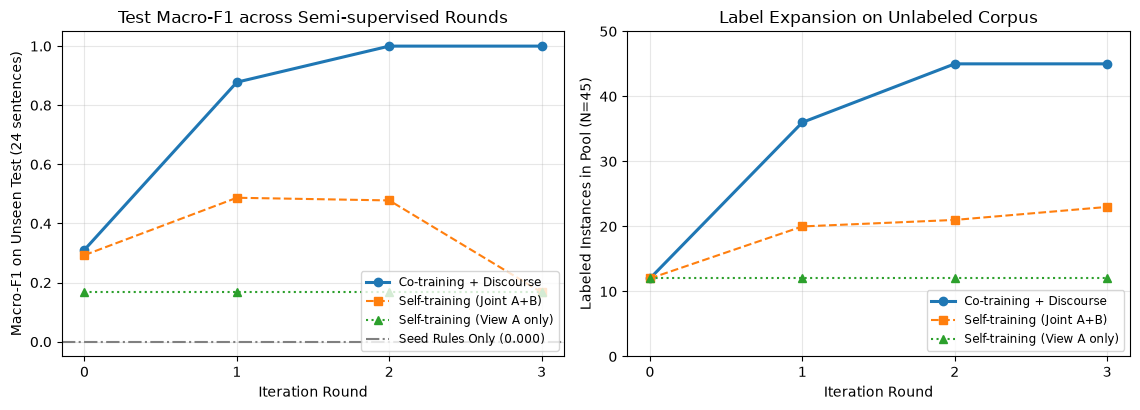

In [3]:
# 1. 初期シードになかった新特徴の獲得例（重み上位）
def top_new_features(clf, vec, is_view_a=True, top_k=4):
    feat_names = vec.get_feature_names_out()
    seed_tokens = {"株式会社", "大学", "空港", "駅", "OS", "DB"}
    rows = []
    for c_idx, cls in enumerate(clf.classes_):
        coefs = clf.coef_[c_idx]
        picked = []
        for f_idx in np.argsort(-coefs):
            fname = feat_names[f_idx]
            if is_view_a:
                if not fname.startswith("suf"):
                    continue
                val = fname.split(":", 1)[1]
                if any(st in val or val in st for st in seed_tokens):
                    continue
            else:
                if not (fname.startswith("R_w:") or fname.startswith("L_w:")):
                    continue
                val = fname.split(":", 1)[1]
                if len(val) == 1 and re.fullmatch(r"[ぁ-ん]", val):
                    continue
            picked.append(f"{fname} ({coefs[f_idx]:+.2f})")
            if len(picked) >= top_k:
                break
        rows.append({"クラス": cls, "新たに獲得された高重み特徴": ", ".join(picked)})
    return pd.DataFrame(rows)

print("=== View A（表記側）で新たに獲得された特徴の例 ===")
display(top_new_features(ct_clf_a, vec_a, is_view_a=True))
print("=== View B（文脈側）で新たに獲得された特徴の例 ===")
display(top_new_features(ct_clf_b, vec_b, is_view_a=False))

# 2. 学習曲線プロット（英語表記ラベル）
rounds = [0, 1, 2, 3]
ct_f1 = [r["Metrics"][3] for r in ct_disc_hist]
ct_cnt = [r["Total"] for r in ct_disc_hist]
sab_f1 = [m_r0[3]] + [h[2][3] for h in self_ab_hist]
sab_cnt = [len(seed_labels)] + [h[1] for h in self_ab_hist]
sa_f1 = [eval_ssl(y_test_ssl, LogisticRegression(C=5.0, max_iter=1000, random_state=42).fit(X_u_a[idx0], [seed_labels[i] for i in idx0]).predict(X_t_a))[3]] + [h[2][3] for h in self_a_hist]
sa_cnt = [len(seed_labels)] + [h[1] for h in self_a_hist]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(rounds, ct_f1, marker="o", linewidth=2.2, label="Co-training + Discourse")
axes[0].plot(rounds, sab_f1, marker="s", linestyle="--", label="Self-training (Joint A+B)")
axes[0].plot(rounds, sa_f1, marker="^", linestyle=":", label="Self-training (View A only)")
axes[0].axhline(m_seed_dir[3], color="gray", linestyle="-.", label="Seed Rules Only (0.000)")
axes[0].set_xticks(rounds)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_xlabel("Iteration Round")
axes[0].set_ylabel("Macro-F1 on Unseen Test (24 sentences)")
axes[0].set_title("Test Macro-F1 across Semi-supervised Rounds")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.3)

axes[1].plot(rounds, ct_cnt, marker="o", linewidth=2.2, label="Co-training + Discourse")
axes[1].plot(rounds, sab_cnt, marker="s", linestyle="--", label="Self-training (Joint A+B)")
axes[1].plot(rounds, sa_cnt, marker="^", linestyle=":", label="Self-training (View A only)")
axes[1].set_xticks(rounds)
axes[1].set_ylim(0, 50)
axes[1].set_xlabel("Iteration Round")
axes[1].set_ylabel("Labeled Instances in Pool (N=45)")
axes[1].set_title("Label Expansion on Unlabeled Corpus")
axes[1].legend(loc="lower right", fontsize=8.5)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 確信度閾値を下げすぎた場合のエラー伝播（セマンティックドリフト）

自己学習・共訓練では、確信度閾値 $\tau$ を高く保ちつつ1ラウンドあたりの追加数を制限することで誤ラベルの混入を防ぎます。逆に閾値を下げすぎて曖昧な候補まで一括で取り込むと、誤った疑似ラベルが次ラウンド以降の訓練を歪める**セマンティックドリフト (Semantic Drift)** が発生します。

In [4]:
# 確信度閾値と1ラウンド追加上限を変えたアブレーション実験
drift_configs = [
    ("安全設定 (tau=0.60, 各クラス上限3)", 0.60, 3),
    ("やや緩和 (tau=0.48, 上限なし)", 0.48, None),
    ("閾値低下 (tau=0.35, 上限なし)", 0.35, None),
]

drift_rows = []
for cname, tau_val, cap_val in drift_configs:
    hist, lab_out, _, _ = run_cotraining(tau=tau_val, max_per_class=cap_val, use_discourse=True)
    r3 = hist[-1]
    drift_rows.append({
        "設定": cname,
        "訓練プール付与数": r3["Total"],
        "訓練プール誤り数": sum(lab_out[i] != unlabeled_data[i][3] for i in lab_out),
        "訓練プール誤り率": r3["PoolErr"],
        "テストMacro-P": r3["Metrics"][1],
        "テストMacro-R": r3["Metrics"][2],
        "テストMacro-F1": r3["Metrics"][3],
    })

drift_df = pd.DataFrame(drift_rows)
display(drift_df)

# 低閾値 (tau=0.35) で混入した誤ラベル事例の例
_, low_lab, _, _ = run_cotraining(tau=0.35, max_per_class=None, use_discourse=True)
err_examples = [
    {
        "候補": unlabeled_data[i][2],
        "誤って付与されたラベル": low_lab[i],
        "実際のクラス(監査用)": unlabeled_data[i][3],
        "文": unlabeled_data[i][1],
    }
    for i in sorted(low_lab)
    if low_lab[i] != unlabeled_data[i][3]
]
print(f"=== tau=0.35 で発生したセマンティックドリフト事例（計 {len(err_examples)} 件中 先頭 5 件） ===")
display(pd.DataFrame(err_examples[:5]))

,設定,訓練プール付与数,訓練プール誤り数,訓練プール誤り率,テストMacro-P,テストMacro-R,テストMacro-F1
0,"安全設定 (tau=0.60, 各クラス上限3)",45,0,0.000,1.00,1.000,1.000
1,"やや緩和 (tau=0.48, 上限なし)",45,0,0.000,1.00,1.000,1.000
2,"閾値低下 (tau=0.35, 上限なし)",45,13,0.289,0.39,0.583,0.465


=== tau=0.35 で発生したセマンティックドリフト事例（計 13 件中 先頭 5 件） ===


,候補,誤って付与されたラベル,実際のクラス(監査用),文
0,銀河研究所,PROD,ORG,なお銀河研究所は来春に新施設を開設する。
1,北風財団,LOC,ORG,これに伴い北風財団の公式窓口が稼働する。
2,若葉図書館,PROD,LOC,帰り道でも若葉図書館の様子を確認した。
3,彩雲アプリ,LOC,PROD,作業後に彩雲アプリの初期設定を済ませた。
4,風車研究所,PROD,ORG,風車研究所は若手向けの奨学金制度を新設した。


### 観察とまとめ（第 1 節）

- **単一ビュー自己学習の限界**: 初期シード一致 12 文では View A のシード表記がラベルを完全に説明してしまうため、View A+B 結合の単一分類器は表記特徴へ重みが偏り、未知表記を含むテスト文への汎化が伸び悩みます（Macro-F1 は Round 3 でも限定的）。View A のみの自己学習では文脈の橋渡しができず、ラベル拡大自体が止まります。
- **共訓練 + one sense per discourse の効果**: View A と View B を独立に保って交互に教師信号を与え、さらに同一文書内の同一表現へラベルを伝播させることで、初期シードにない新表記（`研究所`・`財団`・`美術館`・`図書館`・`アプリ`・`エディタ`）と新文脈（`奨学金制度`・`展示室`・`エラーログ` 等）を段階的に獲得し、シード表現を一切含まないテスト 24 文での Macro-F1 が大きく向上します。
- **セマンティックドリフトへの注意**: 確信度閾値 $\tau$ を下げすぎると（例：`0.35`）、第 1 ラウンドの時点で誤った疑似ラベルが大量に混入し、以後の学習が歪んでテスト性能が大きく低下します。

---

## 2. 遠距離教師あり学習 (Distant Supervision) による訓練データの自動構築とノイズ分析（1-3・関連論文 1章 4）

書籍 1-3「データ：辞書やコーパス」および関連論文 1章 4（Mintz et al., ACL 2009「*Distant supervision for relation extraction without labeled data*」）では、人手で文ごとに正解ラベルを付ける代わりに、既存の知識ベース (KB) とラベルなしテキストを突き合わせて訓練データを自動構築する **遠距離教師あり学習 (Distant Supervision)** が紹介されています。

Distant Supervision の基本仮定は次のとおりです。

> 知識ベース (KB) に登録された 2 つのエンティティ $(e_1, e_2)$ が関係 $r$ を持つとき、**その 2 エンティティが共起する文はすべて関係 $r$ を表している**とみなす（KB に登録のないペアの共起文は負例 `NA` とする）。

この規則により大量の訓練データを低コストで用意できる一方、実際には関係 $r$ を表していない**偶然共起のノイズ (False Positive)** が混入します。まずは KB（3 関係・15 組）とラベルなし日本語コーパス（36 文）を用意し、自動ラベル付けでどれほどノイズが入るか確認しましょう。

In [5]:
# 1. 知識ベース (KB) の三つ組: (主語エンティティ, 関係ラベル, 目的語エンティティ)
kb_triples = [
    ("明光電機", "本社所在地", "東京都"),
    ("北陸製薬", "本社所在地", "富山県"),
    ("瀬戸内造船", "本社所在地", "広島県"),
    ("信濃精密", "本社所在地", "長野県"),
    ("九州食品", "本社所在地", "福岡県"),
    ("光速DB", "開発元", "青葉ソフト"),
    ("星雲翻訳", "開発元", "銀河AI研"),
    ("匠CAD", "開発元", "大和技研"),
    ("彩り解析", "開発元", "風車ラボ"),
    ("隼サーチ", "開発元", "東雲システム"),
    ("蒼穹大学", "キャンパス所在地", "宮城県"),
    ("若葉学院大学", "キャンパス所在地", "愛知県"),
    ("碧海工科大学", "キャンパス所在地", "兵庫県"),
    ("白樺女子大学", "キャンパス所在地", "北海道"),
    ("南風理科大学", "キャンパス所在地", "沖縄県"),
]
kb_map = {(s, o): r for s, r, o in kb_triples}
kb_entities = sorted({s for s, _, _ in kb_triples} | {o for _, _, o in kb_triples}, key=len, reverse=True)

# 2. ラベルなし日本語コーパス（36文; 第2要素の gold_for_audit は事後のノイズ監査専用であり学習には一切使わない）
raw_corpus = [
    # 本社所在地: 関係を表す文 (6)
    ("明光電機は東京都に本社を置く総合メーカーです。", "本社所在地"),
    ("北陸製薬の本社所在地は富山県にあり、研究棟を併設する。", "本社所在地"),
    ("広島県に本社を構える瀬戸内造船は新型貨物船を受注した。", "本社所在地"),
    ("信濃精密は長野県に本社を置く精密部品メーカーだ。", "本社所在地"),
    ("福岡県に本社を置く九州食品は地元食材の商品開発を進める。", "本社所在地"),
    ("東京都に本社を構える明光電機が省エネ家電を発表した。", "本社所在地"),
    # 本社所在地: 偶然共起ノイズ文 (2)
    ("明光電機は東京都で開かれた国際見本市に試作品を展示した。", "NA"),
    ("北陸製薬は富山県内の地域清掃ボランティアに協力した。", "NA"),
    # 開発元: 関係を表す文 (6)
    ("光速DBは青葉ソフトが開発した高速データベース基盤です。", "開発元"),
    ("銀河AI研が開発を手がけた星雲翻訳は専門文書の訳質が高い。", "開発元"),
    ("大和技研が開発した匠CADは設計工程を大幅に短縮する。", "開発元"),
    ("風車ラボが開発を手がけた彩り解析はテキスト感情を可視化する。", "開発元"),
    ("東雲システムが開発した隼サーチは全文検索を高速化する。", "開発元"),
    ("青葉ソフトが開発した光速DBが金融機関へ広く普及した。", "開発元"),
    # 開発元: 偶然共起ノイズ文 (2)
    ("青葉ソフトの社内交流会で光速DBに関するクイズが出題された。", "NA"),
    ("銀河AI研の創立記念イベントで星雲翻訳の記念品が配られた。", "NA"),
    # キャンパス所在地: 関係を表す文 (6)
    ("蒼穹大学は宮城県にキャンパスを構える総合大学です。", "キャンパス所在地"),
    ("愛知県にキャンパスを置く若葉学院大学では地域連携が進む。", "キャンパス所在地"),
    ("兵庫県にキャンパスを構える碧海工科大学は海事研究で知られる。", "キャンパス所在地"),
    ("白樺女子大学は北海道に広大なキャンパスを置く女子大学だ。", "キャンパス所在地"),
    ("沖縄県にキャンパスを構える南風理科大学が新設学部を開いた。", "キャンパス所在地"),
    ("宮城県にある蒼穹大学のキャンパスで学園祭が実施された。", "キャンパス所在地"),
    # キャンパス所在地: 偶然共起ノイズ文 (2)
    ("蒼穹大学の吹奏楽団が宮城県のコンクールで金賞を受けた。", "NA"),
    ("白樺女子大学は北海道の観光協会と防災企画を共催した。", "NA"),
    # KB 上に関係がないエンティティ対の共起文 (12)
    ("明光電機は福岡県で新製品の展示会を開いた。", "NA"),
    ("蒼穹大学は青葉ソフトと共同研究契約を結んだ。", "NA"),
    ("北陸製薬は愛知県に新しい営業所を開設した。", "NA"),
    ("大和技研は東京都で技術カンファレンスを開催した。", "NA"),
    ("隼サーチは広島県の自治体システムへ導入された。", "NA"),
    ("九州食品は宮城県の物産フェアに協賛している。", "NA"),
    ("風車ラボと碧海工科大学は人材育成で連携協定を結んだ。", "NA"),
    ("信濃精密は北海道の産業展へ最新センサーを出展した。", "NA"),
    ("銀河AI研は沖縄県で夏季合宿の勉強会を実施した。", "NA"),
    ("瀬戸内造船の製品説明会が長野県の会場で開かれた。", "NA"),
    ("星雲翻訳は富山県の病院案内システムで試験採用された。", "NA"),
    ("若葉学院大学は東雲システムの検索基盤を授業で活用する。", "NA"),
]

def find_entity_pair(text, entities):
    found = [(text.find(e), e) for e in entities if e in text]
    found.sort()
    assert len(found) == 2, f"Unexpected entity count in: {text}"
    return found[0][1], found[1][1]

def assign_ds_label(e1, e2):
    if (e1, e2) in kb_map:
        return kb_map[(e1, e2)]
    if (e2, e1) in kb_map:
        return kb_map[(e2, e1)]
    return "NA"

ds_rows = []
for text, gold_audit in raw_corpus:
    e1, e2 = find_entity_pair(text, kb_entities)
    ds_lbl = assign_ds_label(e1, e2)
    is_fp = (ds_lbl != "NA") and (gold_audit == "NA")
    ds_rows.append({
        "文": text,
        "エンティティ1": e1,
        "エンティティ2": e2,
        "DS自動ラベル": ds_lbl,
        "実際の関係(監査用)": gold_audit,
        "ノイズ(FP)": is_fp,
    })

ds_df = pd.DataFrame(ds_rows)
print("KB 三つ組数:", len(kb_triples), "/ ラベルなしコーパス文数:", len(ds_df))
print("DS 自動ラベル内訳:", dict(Counter(ds_df["DS自動ラベル"])))
n_pos_ds = int((ds_df["DS自動ラベル"] != "NA").sum())
n_fp_ds = int(ds_df["ノイズ(FP)"].sum())
print(f"正例と自動ラベル付けされた {n_pos_ds} 文のうち偶然共起ノイズ (False Positive): {n_fp_ds} 文 ({n_fp_ds / n_pos_ds:.1%})")
print("\n=== 自動ラベルに混入した偶然共起ノイズ (False Positive) の例 ===")
display(ds_df[ds_df["ノイズ(FP)"]][["エンティティ1", "エンティティ2", "DS自動ラベル", "実際の関係(監査用)", "文"]])

KB 三つ組数: 15 / ラベルなしコーパス文数: 36
DS 自動ラベル内訳: {'本社所在地': 8, '開発元': 8, 'キャンパス所在地': 8, 'NA': 12}
正例と自動ラベル付けされた 24 文のうち偶然共起ノイズ (False Positive): 6 文 (25.0%)

=== 自動ラベルに混入した偶然共起ノイズ (False Positive) の例 ===


,エンティティ1,エンティティ2,DS自動ラベル,実際の関係(監査用),文
6,明光電機,東京都,本社所在地,NA,明光電機は東京都で開かれた国際見本市に試作品を展示した。
7,北陸製薬,富山県,本社所在地,NA,北陸製薬は富山県内の地域清掃ボランティアに協力した。
14,青葉ソフト,光速DB,開発元,NA,青葉ソフトの社内交流会で光速DBに関するクイズが出題された。
15,銀河AI研,星雲翻訳,開発元,NA,銀河AI研の創立記念イベントで星雲翻訳の記念品が配られた。
22,蒼穹大学,宮城県,キャンパス所在地,NA,蒼穹大学の吹奏楽団が宮城県のコンクールで金賞を受けた。
23,白樺女子大学,北海道,キャンパス所在地,NA,白樺女子大学は北海道の観光協会と防災企画を共催した。


### 周辺文脈素性による関係分類とマルチインスタンス集約 (Mintz et al., 2009)

Distant Supervision で自動構築した 36 文を訓練データとし、2 エンティティを `<E1>` / `<E2>` でマスクした上で「エンティティ間の文脈」「左右の周辺文脈」「出現順」の文字 $n$-gram・単語チャンク $n$-gram を抽出し、`LogisticRegression` を学習します。
エンティティ名をマスクするのは、訓練 KB に登場しない**未知のエンティティ対**へ汎化させるためです。

そして、未知のエンティティ対 5 組（各 3 文、合計 15 文）からなる人手評価テストデータ上で次の 2 手法を比較します。

- **(a) 文単位予測**: テスト文 1 文ごとにそのまま関係ラベルを予測する（表現が弱い文で `NA` に誤分類したり、1 文の偶然表現に引きずられたりしやすい）。
- **(b) エンティティペア単位のマルチインスタンス集約 (Mintz et al., 2009)**: 同じエンティティ対 $(e_1, e_2)$ を含む複数文の文脈素性ベクトルを集約（平均）してペア単位で関係を予測する（複数文のうち強い証拠を活かしつつ単発のノイズを相殺できる）。あわせて予測確率平均による集約も確認します。

In [6]:
def extract_context_features(text, e1, e2):
    i1, i2 = text.find(e1), text.find(e2)
    if i1 < i2:
        left, mid, right, order = text[:i1], text[i1 + len(e1):i2], text[i2 + len(e2):], "E1_E2"
    else:
        left, mid, right, order = text[:i2], text[i2 + len(e2):i1], text[i1 + len(e1):], "E2_E1"
    return f"{order} MID:{mid} R:{right[:8]} L:{left[-6:]}"

def ja_chunk_tokenizer(s):
    return re.findall(r"[A-Za-z0-9_]+|[一-龥]+|[ァ-ヴー]+|[ぁ-ん]+", s)

vec_rel = FeatureUnion([
    ("char", TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=1)),
    ("word", TfidfVectorizer(tokenizer=ja_chunk_tokenizer, token_pattern=None, ngram_range=(1, 2), min_df=1)),
])

train_contexts = [
    extract_context_features(r["文"], r["エンティティ1"], r["エンティティ2"])
    for r in ds_rows
]
X_ds = vec_rel.fit_transform(train_contexts)
y_ds = ds_df["DS自動ラベル"].to_numpy()
rel_clf = LogisticRegression(C=3.0, max_iter=1000, random_state=42).fit(X_ds, y_ds)

# 未知のエンティティ対 5 組 × 各 3 文 = 15 文の人手評価テストデータ
test_data = [
    # ペア 1: (星光社, 大阪府) -> 本社所在地
    ("星光社は大阪府に本社を置く精密機器メーカーです。", "星光社", "大阪府", "本社所在地"),
    ("大阪府に本社を構える星光社は今期の増収を見込む。", "星光社", "大阪府", "本社所在地"),
    ("星光社は大阪府の商工会議所で講演を行った。", "星光社", "大阪府", "本社所在地"),
    # ペア 2: (彩雲エディタ, 朝霧ソフト) -> 開発元
    ("彩雲エディタは朝霧ソフトが開発した軽量コードエディタです。", "彩雲エディタ", "朝霧ソフト", "開発元"),
    ("朝霧ソフトが開発を手がけた彩雲エディタの利用者が増えている。", "彩雲エディタ", "朝霧ソフト", "開発元"),
    ("朝霧ソフトの社員紹介ページで彩雲エディタが話題になった。", "彩雲エディタ", "朝霧ソフト", "開発元"),
    # ペア 3: (緑山大学, 京都府) -> キャンパス所在地
    ("緑山大学は京都府にキャンパスを構える私立大学です。", "緑山大学", "京都府", "キャンパス所在地"),
    ("京都府にある緑山大学のキャンパスで学術会議が開かれた。", "緑山大学", "京都府", "キャンパス所在地"),
    ("緑山大学の学生チームが京都府の大会で準優勝した。", "緑山大学", "京都府", "キャンパス所在地"),
    # ペア 4: (海風電機, 静岡県) -> NA
    ("海風電機は静岡県で開催された防災訓練に発電機を提供した。", "海風電機", "静岡県", "NA"),
    ("静岡県の市役所は海風電機の蓄電池を導入した。", "海風電機", "静岡県", "NA"),
    ("海風電機と静岡県の企業は共同で省エネ実験を行った。", "海風電機", "静岡県", "NA"),
    # ペア 5: (銀嶺サーチ, 石川県) -> NA
    ("銀嶺サーチは石川県の観光協会サイトで試験運用された。", "銀嶺サーチ", "石川県", "NA"),
    ("石川県の図書館システムで銀嶺サーチが活用されている。", "銀嶺サーチ", "石川県", "NA"),
    ("銀嶺サーチの技術者が石川県の高校で出張授業を行った。", "銀嶺サーチ", "石川県", "NA"),
]

test_contexts = [extract_context_features(t, e1, e2) for t, e1, e2, _ in test_data]
X_te_rel = vec_rel.transform(test_contexts)
y_te_gold = [g for _, _, _, g in test_data]

# (a) 文単位予測
pred_sent = rel_clf.predict(X_te_rel)
prob_sent = rel_clf.predict_proba(X_te_rel)

# (b) エンティティペア単位のマルチインスタンス集約 (Mintz et al., 2009)
pair_groups = defaultdict(list)
for idx, (_, e1, e2, _) in enumerate(test_data):
    pair_groups[(e1, e2)].append(idx)

pred_pair_feat = [None] * len(test_data)
pred_pair_prob = [None] * len(test_data)
for pair, idxs in pair_groups.items():
    mean_feat = np.asarray(X_te_rel[idxs].mean(axis=0))
    p_feat = rel_clf.predict(mean_feat)[0]
    p_prob = rel_clf.classes_[int(np.argmax(prob_sent[idxs].mean(axis=0)))]
    for i in idxs:
        pred_pair_feat[i] = p_feat
        pred_pair_prob[i] = p_prob

rel_labels = ["本社所在地", "開発元", "キャンパス所在地"]
eval_summary = []
for mname, preds in [
    ("(a) 文単位予測", pred_sent),
    ("(b-1) ペア集約（素性平均 / Mintz 2009）", pred_pair_feat),
    ("(b-2) ペア集約（予測確率平均）", pred_pair_prob),
]:
    mp, mr, mf1, _ = precision_recall_fscore_support(y_te_gold, preds, labels=rel_labels, average="macro", zero_division=0)
    up, ur, uf1, _ = precision_recall_fscore_support(y_te_gold, preds, labels=rel_labels, average="micro", zero_division=0)
    acc = sum(a == b for a, b in zip(y_te_gold, preds)) / len(y_te_gold)
    eval_summary.append({
        "予測手法": mname,
        "全体正解率": round(acc, 3),
        "Macro-Precision": round(mp, 3),
        "Macro-Recall": round(mr, 3),
        "Macro-F1": round(mf1, 3),
        "Micro-F1": round(uf1, 3),
    })

print("=== 未知エンティティ対テスト文（15文）での評価比較 ===")
display(pd.DataFrame(eval_summary))

diff_rows = []
for (t, e1, e2, g), ps, pf in zip(test_data, pred_sent, pred_pair_feat):
    if ps != g or pf != g:
        diff_rows.append({
            "エンティティ対": f"({e1}, {e2})",
            "正解関係": g,
            "文単位予測": ps,
            "ペア集約予測": pf,
            "テスト文": t,
        })
print("=== 文単位予測とペア集約予測が分かれた誤分類・救済事例 ===")
display(pd.DataFrame(diff_rows))

=== 未知エンティティ対テスト文（15文）での評価比較 ===


,予測手法,全体正解率,Macro-Precision,Macro-Recall,Macro-F1,Micro-F1
0,(a) 文単位予測,0.733,0.806,0.778,0.775,0.778
1,(b-1) ペア集約（素性平均 / Mintz 2009）,1.000,1.000,1.000,1.000,1.000
2,(b-2) ペア集約（予測確率平均）,1.000,1.000,1.000,1.000,1.000


=== 文単位予測とペア集約予測が分かれた誤分類・救済事例 ===


,エンティティ対,正解関係,文単位予測,ペア集約予測,テスト文
0,"(星光社, 大阪府)",本社所在地,NA,本社所在地,星光社は大阪府の商工会議所で講演を行った。
1,"(緑山大学, 京都府)",キャンパス所在地,NA,キャンパス所在地,緑山大学の学生チームが京都府の大会で準優勝した。
2,"(銀嶺サーチ, 石川県)",NA,キャンパス所在地,NA,銀嶺サーチは石川県の観光協会サイトで試験運用された。
3,"(銀嶺サーチ, 石川県)",NA,開発元,NA,石川県の図書館システムで銀嶺サーチが活用されている。


### 観察とまとめ（第 2 節）

- **自動構築とノイズのトレードオフ**: KB の 15 組をラベルなし 36 文に当てはめるだけで教師データを即座に生成できましたが、正例ラベルが付いた 24 文のうち **6 文 (25.0%)** は偶然共起のノイズ (False Positive) でした。
- **文単位予測の弱点**: テスト文の中には「星光社は大阪府の商工会議所で講演を行った」（手がかりが弱く `NA` と誤分類：見逃し）や「石川県の図書館システムで銀嶺サーチが活用されている」（「システム」「活用」などの周辺語から誤って `開発元` と予測：誤検出）のように、1 文だけでは判断が揺らぐ文が含まれます。結果として文単位予測は全体正解率 `0.733`、Macro-Precision `0.806`、Macro-Recall `0.778`、Macro-F1 `0.775` にとどまりました。
- **マルチインスタンス集約の効果**: `Mintz et al. (2009)` のようにエンティティ対ごとに複数文の素性を集約することで、明確な根拠を持つ他の文が弱い文を補い、かつ単発の紛らわしい文脈が平均化で抑えられるため、Macro-Precision / Macro-Recall / Macro-F1 のすべてが **`1.000`** へ向上します。